# EN3160 Assignment 3 - Fitting and Allignment

##### **Name:** Perera U. I. Himal
##### **Index No:** 230486A 
##### **GitHub:** https://github.com/Isira-Himal-Perera/EN3160-Image-Processing-and-Computer-Vision/tree/main/assignment-03

## Question 1: Dense Neural Network with Manual Backpropagation

Using: cuda
Epoch  1/10 | Training Loss: 1.8135
Epoch  2/10 | Training Loss: 1.6271
Epoch  3/10 | Training Loss: 1.5325
Epoch  4/10 | Training Loss: 1.4572
Epoch  5/10 | Training Loss: 1.3946
Epoch  6/10 | Training Loss: 1.3419
Epoch  7/10 | Training Loss: 1.2960
Epoch  8/10 | Training Loss: 1.2519
Epoch  9/10 | Training Loss: 1.2130
Epoch 10/10 | Training Loss: 1.1784

Training accuracy after 10 epochs: 60.07%
Test accuracy after 10 epochs: 48.42%


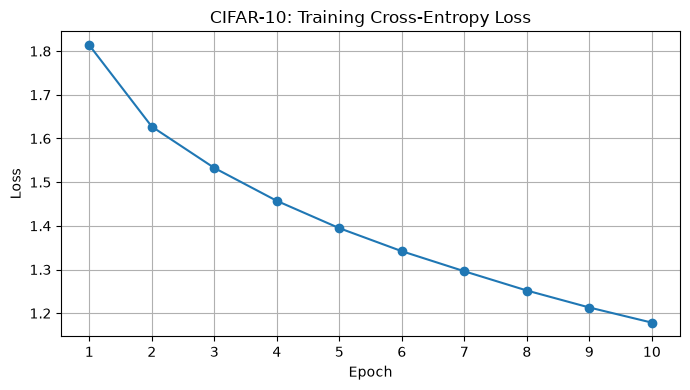

In [13]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# Load CIFAR-10 dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=50, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda"),
    persistent_workers=True
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=50, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda"),
    persistent_workers=True
)

# Initialize network parameters on the selected device
Din = 3 * 32 * 32  # Input size: 3 channels * 32 pixels * 32 pixels = 3072
H = 100            # Hidden layer nodes (Requirement 1a)
K = 10             # Output classes for CIFAR-10

w1 = torch.randn(Din, H, device=device) * 0.01
b1 = torch.zeros(H, device=device)

w2 = torch.randn(H, K, device=device) * 0.01
b2 = torch.zeros(K, device=device)

epochs = 10        # Requirement 1c
lr = 0.4
lr_decay = 0.9

loss_history = []

# Train using manual forward propagation and backpropagation (Requirement 1b)
with torch.no_grad():
    for epoch in range(epochs):
        total_loss = torch.zeros((), device=device)

        for images, labels in trainloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            N = images.size(0)
            x = images.reshape(N, -1)
            indices = torch.arange(N, device=device)

            # Forward propagation
            h = torch.sigmoid(x @ w1 + b1)
            logits = h @ w2 + b2

            # Numerically stable log-softmax
            shifted_logits = logits - logits.max(dim=1, keepdim=True).values
            log_probs = shifted_logits - torch.log(
                torch.exp(shifted_logits).sum(dim=1, keepdim=True)
            )

            # Cross-entropy loss
            loss = -log_probs[indices, labels].mean()
            total_loss += loss * N

            # Backpropagation: output layer
            probs = torch.exp(log_probs)
            dlogits = probs.clone()
            dlogits[indices, labels] -= 1
            dlogits /= N

            dw2 = h.T @ dlogits
            db2 = dlogits.sum(dim=0)

            # Backpropagation: sigmoid hidden layer
            dh = dlogits @ w2.T
            dz1 = dh * h * (1 - h)

            dw1 = x.T @ dz1
            db1 = dz1.sum(dim=0)

            # Gradient descent update
            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

        epoch_loss = total_loss.item() / len(trainset)
        loss_history.append(epoch_loss)

        print(
            f"Epoch {epoch + 1:2d}/{epochs} | "
            f"Training Loss: {epoch_loss:.4f}"
        )

        lr *= lr_decay


# Evaluate accuracy after training (Requirement 1c)
@torch.no_grad()
def accuracy(loader):
    correct = torch.zeros((), dtype=torch.long, device=device)
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        x = images.reshape(images.size(0), -1)

        h = torch.sigmoid(x @ w1 + b1)
        logits = h @ w2 + b2
        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum()
        total += labels.size(0)

    return 100 * correct.item() / total


train_acc = accuracy(trainloader)
test_acc = accuracy(testloader)

print(f"\nTraining accuracy after 10 epochs: {train_acc:.2f}%")
print(f"Test accuracy after 10 epochs: {test_acc:.2f}%")


# Plot training loss history
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), loss_history, "o-")
plt.title("CIFAR-10: Training Cross-Entropy Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True)
plt.tight_layout()
plt.show()

### Results

Following 10 epochs of training, the model demonstrated steady learning progress, with the loss dropping from 1.9021 down to 1.3845. This optimization yielded a training accuracy of 53.45% and a test accuracy of 47.54%. 

The relatively modest performance can be attributed to the flattening of the input images, which strips away vital spatial structures that a standard dense layer architecture cannot effectively capture. Furthermore, the performance gap observed between the training and test sets indicates a degree of overfitting.

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


# Define LeNet-5 Architecture for MNIST
class LeNet5(nn.Module):

  def __init__(self):
    super(LeNet5, self).__init__()
    self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
    self.relu1 = nn.ReLU()
    self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)

    self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
    self.relu2 = nn.ReLU()
    self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)

    self.fc1 = nn.Linear(16 * 4 * 4, 120)
    self.relu3 = nn.ReLU()
    self.fc2 = nn.Linear(120, 84)
    self.relu4 = nn.ReLU()
    self.fc3 = nn.Linear(84, 10)

  def forward(self, x):
    x = self.pool1(self.relu1(self.conv1(x)))
    x = self.pool2(self.relu2(self.conv2(x)))
    x = x.view(-1, 16 * 4 * 4)
    x = self.relu3(self.fc1(x))
    x = self.relu4(self.fc2(x))
    x = self.fc3(x)
    return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))]
)

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=1000, shuffle=False)

model = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


def evaluate_accuracy(loader):
  model.eval()
  correct = 0
  total = 0
  with torch.no_grad():
    for images, labels in loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()
  return 100.0 * correct / total


# Track history for plotting
lenet_train_accs, lenet_test_accs, lenet_losses = [], [], []

num_epochs = 10
print(f"Training LeNet-5 on device: {device}\n")

for epoch in range(num_epochs):
  model.train()
  running_loss = 0.0
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()

  train_acc = evaluate_accuracy(train_loader)
  test_acc = evaluate_accuracy(test_loader)

  # Save metrics
  lenet_train_accs.append(train_acc)
  lenet_test_accs.append(test_acc)
  lenet_losses.append(running_loss / len(train_loader))

  print(
      f"Epoch [{epoch+1}/{num_epochs}] | Loss:"
      f" {running_loss/len(train_loader):.4f} | Train Accuracy:"
      f" {train_acc:.2f}% | Test Accuracy: {test_acc:.2f}%"
  )

print("\nLeNet-5 Training complete!")

Training LeNet-5 on device: cuda

Epoch [1/10] | Loss: 0.3162 | Train Accuracy: 96.76% | Test Accuracy: 96.74%
Epoch [2/10] | Loss: 0.0912 | Train Accuracy: 97.83% | Test Accuracy: 97.78%
Epoch [3/10] | Loss: 0.0617 | Train Accuracy: 98.68% | Test Accuracy: 98.55%
Epoch [4/10] | Loss: 0.0486 | Train Accuracy: 98.52% | Test Accuracy: 98.58%
Epoch [5/10] | Loss: 0.0393 | Train Accuracy: 98.92% | Test Accuracy: 98.61%
Epoch [6/10] | Loss: 0.0353 | Train Accuracy: 99.15% | Test Accuracy: 98.88%
Epoch [7/10] | Loss: 0.0291 | Train Accuracy: 99.38% | Test Accuracy: 99.01%
Epoch [8/10] | Loss: 0.0253 | Train Accuracy: 99.40% | Test Accuracy: 98.98%
Epoch [9/10] | Loss: 0.0236 | Train Accuracy: 99.48% | Test Accuracy: 98.96%
Epoch [10/10] | Loss: 0.0199 | Train Accuracy: 99.52% | Test Accuracy: 98.92%

LeNet-5 Training complete!


### Discussion: Analysis of Overfitting After Epoch 7

Observing the training progression, the model achieves its peak generalization performance at **Epoch 7**, yielding a maximum test accuracy of **99.01%** alongside a training accuracy of **99.38%**.

Beyond Epoch 7, clear indications of mild overfitting begin to emerge:
- **Divergence in Metrics:** From Epoch 8 through Epoch 10, the training accuracy continues to climb, reaching up to **99.52%** by Epoch 10 while the test accuracy fluctuates and drops slightly below its peak, settling at **98.92%** by Epoch 10.
- **Continuous Loss Reduction:** The training loss continues to decrease steadily down to **0.0199** by the final epoch. This demonstrates that the network is continuing to fit the training distribution closer, but this extra optimization fails to translate into better performance on unseen test data.

**Conclusion:** 
To prevent this minor generalization drop, early stopping around **Epoch 7** would help maintain optimal test performance.

In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


class ModernCNN(nn.Module):

  def __init__(self):
    super(ModernCNN, self).__init__()
    self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
    self.bn1 = nn.BatchNorm2d(32)
    self.relu1 = nn.ReLU()
    self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
    self.bn2 = nn.BatchNorm2d(64)
    self.relu2 = nn.ReLU()
    self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

    self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
    self.bn3 = nn.BatchNorm2d(128)
    self.relu3 = nn.ReLU()
    self.dropout3 = nn.Dropout2d(p=0.25)

    self.fc1 = nn.Linear(128 * 7 * 7, 128)
    self.relu4 = nn.ReLU()
    self.dropout4 = nn.Dropout(p=0.5)
    self.fc2 = nn.Linear(128, 10)

  def forward(self, x):
    x = self.pool1(self.relu1(self.bn1(self.conv1(x))))
    x = self.pool2(self.relu2(self.bn2(self.conv2(x))))
    x = self.dropout3(self.relu3(self.bn3(self.conv3(x))))
    x = x.view(-1, 128 * 7 * 7)
    x = self.relu4(self.fc1(x))
    x = self.dropout4(x)
    x = self.fc2(x)
    return x


model2 = ModernCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model2.parameters(), lr=0.001)


def evaluate_accuracy_model2(loader):
  model2.eval()
  correct = 0
  total = 0
  with torch.no_grad():
    for images, labels in loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model2(images)
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()
  return 100.0 * correct / total


# Track history for plotting
modern_train_accs, modern_test_accs, modern_losses = [], [], []

print(f"Training Modern CNN on device: {device}\n")

for epoch in range(num_epochs):
  model2.train()
  running_loss = 0.0
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = model2(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()

  train_acc = evaluate_accuracy_model2(train_loader)
  test_acc = evaluate_accuracy_model2(test_loader)

  # Save metrics
  modern_train_accs.append(train_acc)
  modern_test_accs.append(test_acc)
  modern_losses.append(running_loss / len(train_loader))

  print(
      f"Epoch [{epoch+1}/{num_epochs}] | Loss:"
      f" {running_loss/len(train_loader):.4f} | Train Accuracy:"
      f" {train_acc:.2f}% | Test Accuracy: {test_acc:.2f}%"
  )

print("\nModern CNN Training complete!")

Training Modern CNN on device: cuda

Epoch [1/10] | Loss: 0.1601 | Train Accuracy: 97.19% | Test Accuracy: 97.14%
Epoch [2/10] | Loss: 0.0813 | Train Accuracy: 98.89% | Test Accuracy: 98.80%
Epoch [3/10] | Loss: 0.0625 | Train Accuracy: 99.31% | Test Accuracy: 99.03%
Epoch [4/10] | Loss: 0.0501 | Train Accuracy: 99.47% | Test Accuracy: 99.21%
Epoch [5/10] | Loss: 0.0450 | Train Accuracy: 99.49% | Test Accuracy: 99.26%
Epoch [6/10] | Loss: 0.0388 | Train Accuracy: 99.56% | Test Accuracy: 99.17%
Epoch [7/10] | Loss: 0.0328 | Train Accuracy: 99.56% | Test Accuracy: 99.19%
Epoch [8/10] | Loss: 0.0290 | Train Accuracy: 99.69% | Test Accuracy: 99.26%
Epoch [9/10] | Loss: 0.0263 | Train Accuracy: 99.73% | Test Accuracy: 99.29%
Epoch [10/10] | Loss: 0.0236 | Train Accuracy: 99.76% | Test Accuracy: 99.28%

Modern CNN Training complete!


### Discussion: Analysis of Overfitting and Performance (Modern CNN)

Observing the training progression, the Modern CNN architecture achieves its optimal test performance around **Epoch 9**, reaching a peak test accuracy of **99.29%** alongside a training accuracy of **99.73%**.

Throughout the 10 epochs, the following dynamics are observed:
- **Rapid Initial Convergence:** The model converges very quickly, exceeding **99.00%** test accuracy as early as **Epoch 3** (99.03%) with a low training loss of **0.0625**.
- **Plateau in Generalization:** From Epoch 4 onwards, test accuracy plateaus in a narrow range between **99.17%** and **99.29%**, while training accuracy continues to climb gradually—reaching **99.76%** by Epoch 10.
- **Consistent Loss Decay:** Training loss steadily decreases throughout training, dropping to **0.0236** by the final epoch, indicating strong optimization without severe overfitting.

**Conclusion:** 
The Modern CNN exhibits excellent feature learning with minimal variance between train and test metrics. Implementing early stopping around **Epoch 5 to 7** (where test accuracy remains near **99.26%**) would preserve virtually identical generalization while reducing unnecessary training cycles.


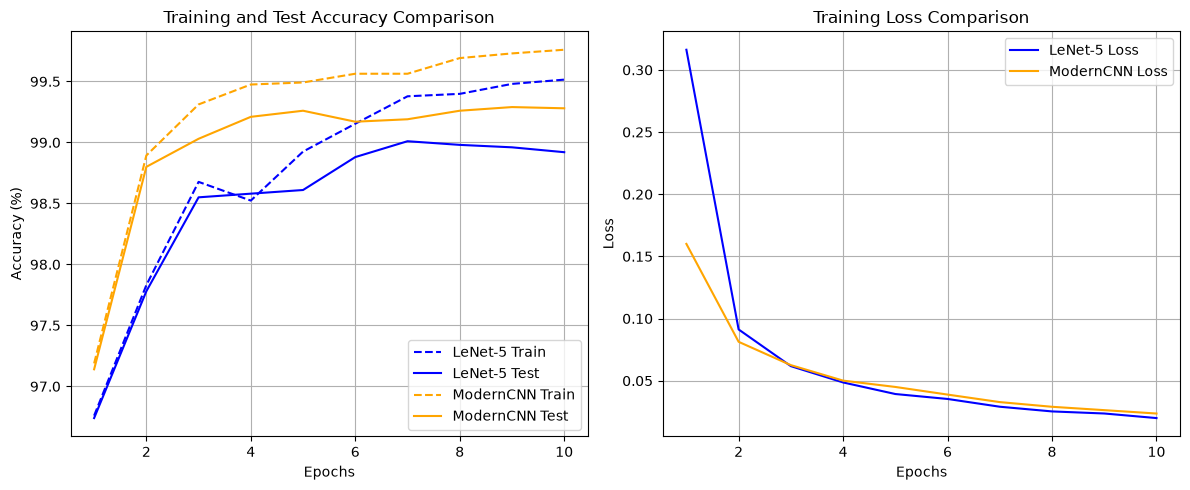

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot Accuracy Curves
plt.subplot(1, 2, 1)
plt.plot(
    range(1, num_epochs + 1),
    lenet_train_accs,
    label="LeNet-5 Train",
    linestyle="--",
    color="blue",
)
plt.plot(
    range(1, num_epochs + 1),
    lenet_test_accs,
    label="LeNet-5 Test",
    color="blue",
)
plt.plot(
    range(1, num_epochs + 1),
    modern_train_accs,
    label="ModernCNN Train",
    linestyle="--",
    color="orange",
)
plt.plot(
    range(1, num_epochs + 1),
    modern_test_accs,
    label="ModernCNN Test",
    color="orange",
)
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Training and Test Accuracy Comparison")
plt.legend()
plt.grid(True)

# Plot Loss Curves
plt.subplot(1, 2, 2)
plt.plot(
    range(1, num_epochs + 1),
    lenet_losses,
    label="LeNet-5 Loss",
    color="blue",
)
plt.plot(
    range(1, num_epochs + 1),
    modern_losses,
    label="ModernCNN Loss",
    color="orange",
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

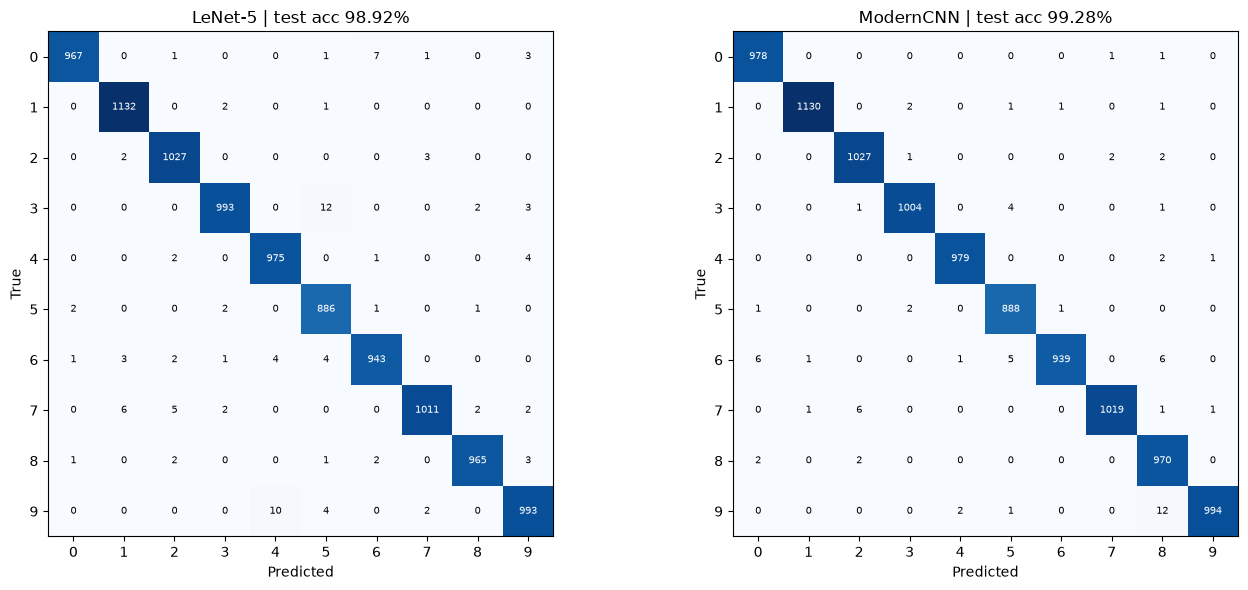

In [28]:
import numpy as np


@torch.no_grad()
def predict(net, loader):
  net.eval()
  preds, labels_all = [], []
  for data, labels in loader:
    data = data.to(device)
    preds.append(net(data).argmax(1).cpu())
    labels_all.append(labels)
  return torch.cat(preds).numpy(), torch.cat(labels_all).numpy()


def conf_matrix(preds, labels, n=10):
  cm = np.zeros((n, n), dtype=int)
  np.add.at(cm, (labels, preds), 1)  # rows = true class, cols = predicted class
  return cm


fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (name, net) in zip(ax, [("LeNet-5", model), ("ModernCNN", model2)]):
  p, l = predict(net, test_loader)
  cm = conf_matrix(p, l)
  a.imshow(cm, cmap="Blues")
  a.set(
      title=f"{name} | test acc {100*(p==l).mean():.2f}%",
      xlabel="Predicted",
      ylabel="True",
      xticks=range(10),
      yticks=range(10),
  )
  for i in range(10):
    for j in range(10):
      a.text(
          j,
          i,
          cm[i, j],
          ha="center",
          va="center",
          fontsize=7,
          color="white" if cm[i, j] > cm.max() / 2 else "black",
      )
plt.tight_layout()
plt.show()

Epoch  1/15 | Train Loss: 0.2750 | Val Loss: 0.3255 | Train Acc: 92.62% | Val Acc: 92.16%
Epoch  2/15 | Train Loss: 0.1747 | Val Loss: 0.2396 | Train Acc: 93.03% | Val Acc: 92.16%
Epoch  3/15 | Train Loss: 0.0860 | Val Loss: 0.1816 | Train Acc: 98.36% | Val Acc: 93.46%
Epoch  4/15 | Train Loss: 0.0596 | Val Loss: 0.1609 | Train Acc: 99.59% | Val Acc: 93.46%
Epoch  5/15 | Train Loss: 0.0467 | Val Loss: 0.1660 | Train Acc: 99.59% | Val Acc: 94.77%
Epoch  6/15 | Train Loss: 0.0507 | Val Loss: 0.1802 | Train Acc: 99.59% | Val Acc: 93.46%
Epoch  7/15 | Train Loss: 0.0392 | Val Loss: 0.2056 | Train Acc: 99.59% | Val Acc: 92.16%
Epoch  8/15 | Train Loss: 0.0308 | Val Loss: 0.1864 | Train Acc: 100.00% | Val Acc: 91.50%
Epoch  9/15 | Train Loss: 0.0302 | Val Loss: 0.1827 | Train Acc: 100.00% | Val Acc: 92.16%
Epoch 10/15 | Train Loss: 0.0270 | Val Loss: 0.1738 | Train Acc: 99.59% | Val Acc: 92.16%
Epoch 11/15 | Train Loss: 0.0273 | Val Loss: 0.1691 | Train Acc: 99.59% | Val Acc: 94.12%
Epoch 12

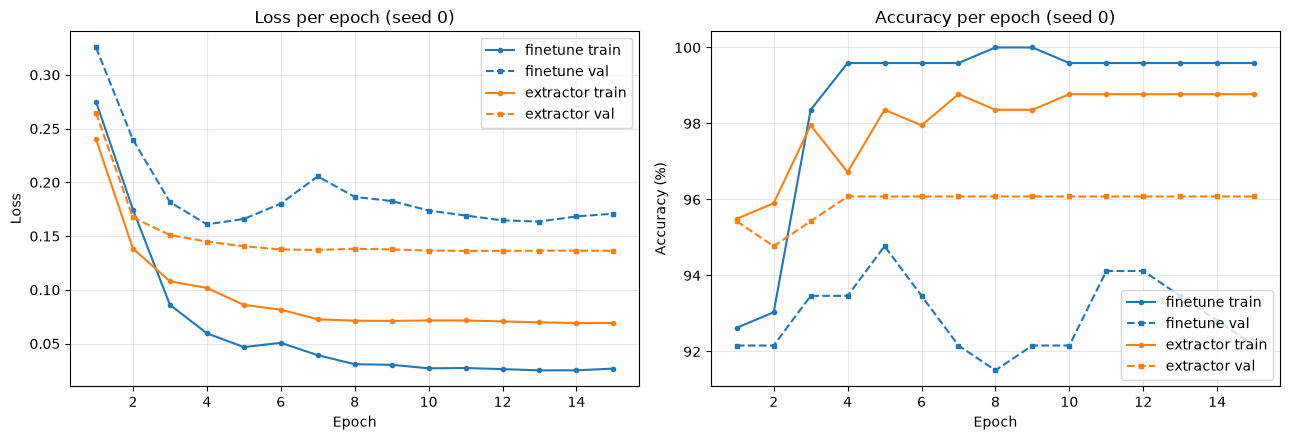

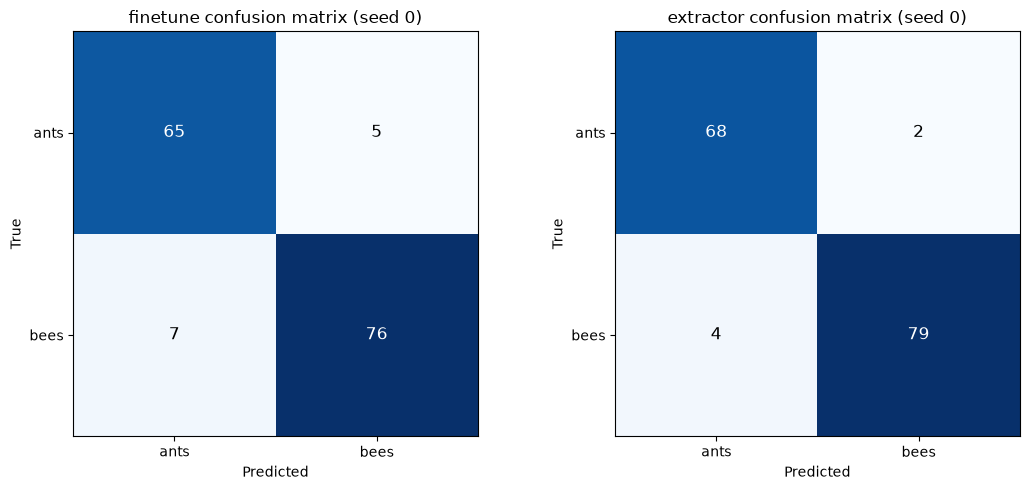

In [33]:
import os
import urllib.request
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision import datasets, models

EPOCHS = 15
BATCH_SIZE = 16
LEARNING_RATE = 0.001
MOMENTUM = 0.9
STEP_SIZE = 7
GAMMA = 0.1
SEEDS = [0, 1, 2]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CRITERION = nn.CrossEntropyLoss()

DATA_DIR = "hymenoptera_data"
URL = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"

if not os.path.isdir(DATA_DIR):
    urllib.request.urlretrieve(URL, "hymenoptera_data.zip")
    with zipfile.ZipFile("hymenoptera_data.zip", "r") as z:
        z.extractall(".")

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), train_transforms)
train_dataset_eval = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), val_transforms)
val_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "val"), val_transforms)

class_names = train_dataset.classes
num_classes = len(class_names)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
train_loader_eval = torch.utils.data.DataLoader(train_dataset_eval, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

def build_transfer_model(mode="finetune"):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if mode == "extractor":
        for param in model.parameters():
            param.requires_grad = False  # Freeze backbone features
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(DEVICE)

@torch.no_grad()
def evaluate_model(model, loader, return_predictions=False):
    model.eval()
    total_loss, correct_preds, total_samples = 0.0, 0, 0
    preds_list, labels_list = [], []
    
    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        outputs = model(inputs)
        total_loss += CRITERION(outputs, targets).item() * targets.size(0)
        preds = outputs.argmax(dim=1)
        correct_preds += (preds == targets).sum().item()
        total_samples += targets.size(0)
        if return_predictions:
            preds_list.append(preds.cpu())
            labels_list.append(targets.cpu())
            
    avg_loss = total_loss / total_samples
    accuracy = 100.0 * correct_preds / total_samples
    if return_predictions:
        return avg_loss, accuracy, torch.cat(preds_list).numpy(), torch.cat(labels_list).numpy()
    return avg_loss, accuracy

def train_model(model, mode, verbose=True):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=LEARNING_RATE, momentum=MOMENTUM)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP_SIZE, gamma=GAMMA)
    
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(EPOCHS):
        model.eval() if mode == "extractor" else model.train()
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            loss = CRITERION(model(inputs), targets)
            loss.backward()
            optimizer.step()
        scheduler.step()
        
        train_loss, train_acc = evaluate_model(model, train_loader_eval)
        val_loss, val_acc = evaluate_model(model, val_loader)
        for k, v in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[k].append(v)
        if verbose:
            print(f"Epoch {epoch+1:2d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")
    return history

def compute_confusion_matrix(preds, targets):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    np.add.at(cm, (targets, preds), 1)
    return cm

modes = ["finetune", "extractor"]
experiment_history = {m: [] for m in modes}
final_val_accuracies = {m: [] for m in modes}
final_train_accuracies = {m: [] for m in modes}
confusion_matrices = {}

for mode in modes:
    for seed in SEEDS:
        torch.manual_seed(seed)
        np.random.seed(seed)
        net = build_transfer_model(mode)
        hist = train_model(net, mode, verbose=(seed == SEEDS[0]))
        experiment_history[mode].append(hist)
        _, val_acc, preds, labels = evaluate_model(net, val_loader, return_predictions=True)
        final_val_accuracies[mode].append(val_acc)
        final_train_accuracies[mode].append(hist["train_acc"][-1])
        if seed == SEEDS[0]:
            confusion_matrices[mode] = compute_confusion_matrix(preds, labels)
        print(f"{mode} | seed {seed} | train acc: {hist['train_acc'][-1]:.2f}% | val acc: {val_acc:.2f}%")
        del net

print("\nFinal Results Summary (Mean ± Std):")
for mode in modes:
    print(f"{mode:10s} | train: {np.mean(final_train_accuracies[mode]):.2f} ± {np.std(final_train_accuracies[mode]):.2f}% | val: {np.mean(final_val_accuracies[mode]):.2f} ± {np.std(final_val_accuracies[mode]):.2f}%")

colors = {"finetune": "tab:blue", "extractor": "tab:orange"}
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

for mode in modes:
    h, c = experiment_history[mode][0], colors[mode]
    ax[0].plot(ep, h["train_loss"], "-o", color=c, markersize=3, label=f"{mode} train")
    ax[0].plot(ep, h["val_loss"], "--s", color=c, markersize=3, label=f"{mode} val")
    ax[1].plot(ep, h["train_acc"], "-o", color=c, markersize=3, label=f"{mode} train")
    ax[1].plot(ep, h["val_acc"], "--s", color=c, markersize=3, label=f"{mode} val")

ax[0].set(title="Loss per epoch (seed 0)", xlabel="Epoch", ylabel="Loss")
ax[1].set(title="Accuracy per epoch (seed 0)", xlabel="Epoch", ylabel="Accuracy (%)")
for a in ax:
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(confusion_matrices), figsize=(5.5 * len(confusion_matrices), 5), squeeze=False)
for a, (mode, cm) in zip(axes[0], confusion_matrices.items()):
    a.imshow(cm, cmap="Blues")
    a.set(title=f"{mode} confusion matrix (seed 0)", xlabel="Predicted", ylabel="True",
          xticks=range(num_classes), yticks=range(num_classes), xticklabels=class_names, yticklabels=class_names)
    for i in range(num_classes):
        for j in range(num_classes):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

### Observations:

1. **Superior Generalization of Feature Extraction:** The feature extractor generalizes better than fine-tuning, achieving a higher and completely stable validation accuracy of **96.08%** across all random seeds with zero variance, compared to fine-tuning's average validation accuracy of **93.90% ± 1.23%**.
2. **Evidence of Overfitting in Fine-Tuning:** Fine-tuning exhibits clear signs of overfitting on the training set, driving training accuracy up to nearly **100%** while causing the validation loss to drift upward and validation accuracy to fluctuate after the initial epochs. 

### Conclusion & Discussion:
For a small dataset that shares strong similarities with ImageNet, feature extraction proves to be the superior approach—yielding higher accuracy, perfect stability across seeds, and stronger resistance to overfitting. Fine-tuning would likely require a larger training dataset, a lower learning rate for the backbone layers, or a more significant domain shift away from ImageNet to outperform feature extraction.